# Entrenamiento y Prueba (train_test_split)

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Para saber si un modelo realmente sirve, no lo evaluamos con los mismos datos con que aprendió. Dividimos los datos en **entrenamiento** y **prueba**.

## 1. El problema

Tenemos precios de carros **BMW** usados. Queremos predecir el precio a partir del **millaje** y la **edad**. Usaremos `train_test_split` de scikit-learn para separar los datos.

In [1]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/carprices_tt.csv')
df.head()

,Mileage,Age(yrs),Sell Price($)
0,69000,6,18000
1,35000,3,34000
2,57000,5,26100
3,22500,2,40000
4,46000,4,31500


In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

**Millaje vs. Precio de venta.** Se ve una relación lineal (más millas → menor precio).

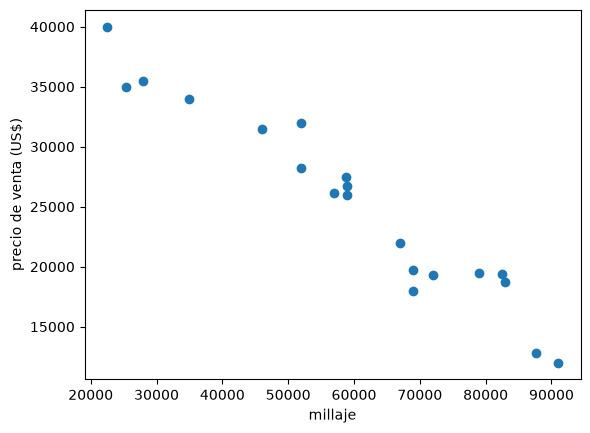

In [3]:
plt.scatter(df['Mileage'], df['Sell Price($)'])
plt.xlabel('millaje'); plt.ylabel('precio de venta (US$)')
plt.show()

**Edad vs. Precio de venta.** También es lineal (más años → menor precio).

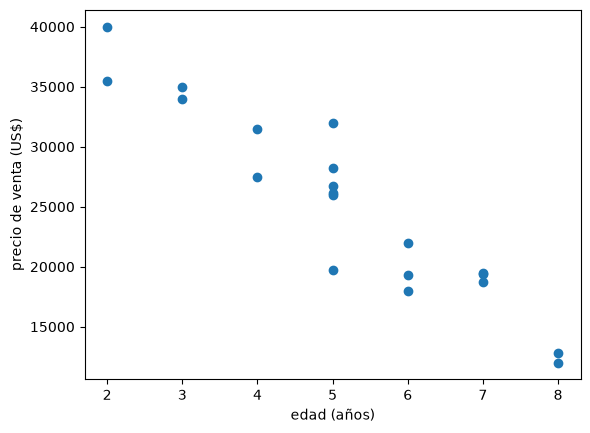

In [4]:
plt.scatter(df['Age(yrs)'], df['Sell Price($)'])
plt.xlabel('edad (años)'); plt.ylabel('precio de venta (US$)')
plt.show()

## 2. ¿Por qué separar los datos?

Si evaluamos el modelo con los mismos datos que usó para aprender, es como hacer un examen con las preguntas que ya se enseñaron en clase: parecerá perfecto aunque no lo sea. Por eso apartamos una parte **solo para probar**.

Definimos entrada (`X` = millaje y edad) y salida (`y` = precio).

In [5]:
X = df[['Mileage','Age(yrs)']]
X

,Mileage,Age(yrs)
0,69000,6
1,35000,3
2,57000,5
3,22500,2
4,46000,4
5,59000,5
6,52000,5
7,72000,6
8,91000,8
9,67000,6


In [6]:
y = df['Sell Price($)']
y

0     18000
1     34000
2     26100
3     40000
4     31500
5     26750
6     32000
7     19300
8     12000
9     22000
10    18700
11    19500
12    26000
13    27500
14    19400
15    35000
16    35500
17    19700
18    12800
19    28200
Name: Sell Price($), dtype: int64

Dividimos: 80% para entrenar, 20% para probar. `random_state` fija el azar para que el resultado sea reproducible.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

In [8]:
X_train

,Mileage,Age(yrs)
3,22500,2
18,87600,8
13,58780,4
2,57000,5
14,82450,7
8,91000,8
17,69000,5
16,28000,2
19,52000,5
12,59000,5


In [9]:
X_test

,Mileage,Age(yrs)
7,72000,6
10,83000,7
5,59000,5
6,52000,5


## 3. Entrenamos y evaluamos

Entrenamos **solo** con los datos de entrenamiento.

In [10]:
from sklearn.linear_model import LinearRegression
clf = LinearRegression()
clf.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ -0.29,-942.57]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Mileage','Age(yrs)']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.694e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


Predecimos sobre los datos de prueba (que el modelo **nunca vio**).

In [11]:
y_pred = clf.predict(X_test)
y_pred

array([20474.0745775 , 16352.07892168, 25174.14834912, 27197.42175439])

Comparamos con los valores reales de prueba.

In [12]:
y_test

7     19300
10    18700
5     26750
6     32000
Name: Sell Price($), dtype: int64

El **score** (R²) sobre los datos de prueba mide qué tan bien generaliza el modelo.

In [13]:
clf.score(X_test, y_test)

0.733233959309014

Gráfica: precio real vs. precio predicho en el conjunto de prueba.

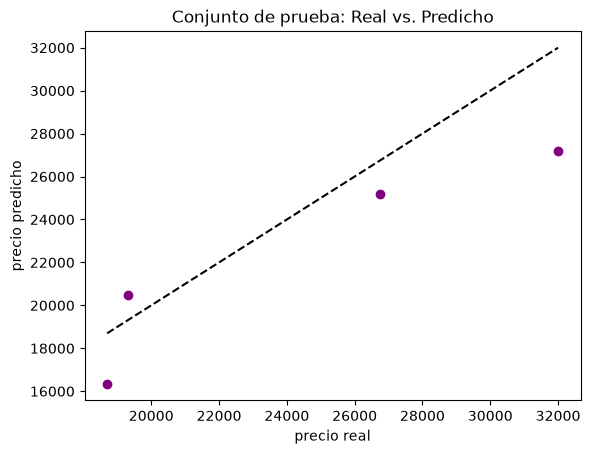

In [14]:
plt.scatter(y_test, y_pred, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
plt.xlabel('precio real'); plt.ylabel('precio predicho')
plt.title('Conjunto de prueba: Real vs. Predicho')
plt.show()

## Ejercicio práctico

**Enunciado:** Usando el mismo conjunto de carros, (1) entrenar un modelo con una división **75% / 25%**, (2) medir su score en el conjunto de prueba y (3) predecir el precio de un BMW con **45,000 millas y 4 años**.

**Paso 1.** Nueva división 75/25.

In [15]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
print("Entrenamiento:", len(Xtr), " | Prueba:", len(Xte))

Entrenamiento: 15  | Prueba: 5


**Paso 2.** Entrenamos y medimos el score en prueba.

In [16]:
clf2 = LinearRegression()
clf2.fit(Xtr, ytr)
print(f"Score (R²) en prueba: {clf2.score(Xte, yte):.4f}")

Score (R²) en prueba: 0.8874


**Paso 3.** Predecimos el precio de un BMW con 45,000 millas y 4 años.

In [17]:
precio = clf2.predict([[45000, 4]])
print(f"Precio estimado (45000 mi, 4 años): US$ {precio[0]:,.2f}")

Precio estimado (45000 mi, 4 años): US$ 31,305.52


/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


**Conclusión:** el modelo entrenado con el 75% de los datos logra un buen score sobre el 25% de prueba, lo que indica que **generaliza bien** a carros que no había visto. La predicción para el carro nuevo es coherente con la tendencia de los datos.